# Task 4: acople de una epidemia (SIR) al hospital
CC2017 Modelación y Simulación, UVG · Hoja de Trabajo 7 · Grupo 5.

| Inciso | Contenido | Estado |
|---|---|---|
| 4.1a | Integrar el SIR (200 días), graficar λepi(t) junto con λ y reportar el pico | **Hecho** (abajo) |
| 4.1b | Llegadas con λ(t) por adelgazamiento; 100 réplicas del modelo sin espera con las camas recomendadas en el Task 3.1 | Pendiente |
| 4.1c | Camas de contingencia para que los desviados durante la ola no superen 5 % | Pendiente |
| 4.1d | Dos fenómenos que el modelo de un solo sentido ignora y su efecto | Pendiente |

In [1]:
import sys, json, pathlib, math
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt

RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from hospital_uci import teoria as T, simulador as S, sir

FIG, DAT = RAIZ / "resultados" / "figuras", RAIZ / "resultados" / "datos"
FIG.mkdir(parents=True, exist_ok=True); DAT.mkdir(parents=True, exist_ok=True)
AZUL, NARANJA, GRIS = "#0072B2", "#D55E00", "#6b7280"      # azul/naranja: distinguibles con daltonismo
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "font.size": 10,
                     "axes.titlesize": 11, "legend.frameon": False})
P = T.parametros_grupo(5)
lam, mu, c = P["lam"], P["mu"], P["c"]
RES = {}      # resultados numéricos de este notebook (se guardan en JSON al final)

def md_tabla(nombre, df, **kw):
    return df

## Task 4.1a — Modelo SIR y λ_epi(t)
$\dot S=-\beta SI/N$, $\dot I=\beta SI/N-\gamma I$, $\dot R=\gamma I$; $\lambda_{epi}(t)=p_h\,\beta\,S(t)I(t)/N$, $\lambda(t)=\lambda+\lambda_{epi}(t)$.
**Método:** Runge–Kutta clásico de 4.º orden con paso fijo (explícito, un paso, error global $O(\Delta t^4)$; el sistema es suave y no rígido). Se contrasta con DOP853 (tolerancia $10^{-11}$) y se reduce el paso.

In [2]:
SIRP = dict(beta=0.30, gamma=0.2, N=500_000, I0=100, R0=0, dias=200.0, p_h=0.0002)
assert 500_000 - 100 - 0 == 499_900
ref = sir.integrar_referencia(dt=0.01, **SIRP); pr = sir.pico(ref)
filas = []
for dt in [1.0, 0.5, 0.1, 0.05, 0.01]:
    cv = sir.integrar_sir(dt=dt, **SIRP); pk = sir.pico(cv)
    k_ref = np.round(cv["t"] / 0.01).astype(int)
    filas.append({"paso dt (días)": dt, "día del pico": pk["dia"], "pico λ_epi (pac/día)": pk["valor"],
                  "dif. rel. del pico vs referencia": abs(pk["valor"] - pr["valor"]) / pr["valor"],
                  "máx |λ_epi − referencia| (pac/día)": float(np.max(np.abs(cv["lambda_epi"] - ref["lambda_epi"][k_ref])))})
conv = pd.DataFrame(filas)
RES["sir_convergencia"] = conv.to_dict("records"); RES["sir_referencia_dop853"] = pr
md_tabla("sir_convergencia", conv.assign(**{"pico λ_epi (pac/día)": conv["pico λ_epi (pac/día)"].round(6), "dif. rel. del pico vs referencia": conv["dif. rel. del pico vs referencia"].map(lambda v: f"{v:.1e}"),
                                           "máx |λ_epi − referencia| (pac/día)": conv["máx |λ_epi − referencia| (pac/día)"].map(lambda v: f"{v:.1e}")}))
print("Referencia DOP853 (malla 0.01 d): pico", pr); conv

Referencia DOP853 (malla 0.01 d): pico {'dia': 68.64, 'valor': 1.3212683346356908}


,paso dt (días),día del pico,pico λ_epi (pac/día),dif. rel. del pico vs referencia,máx |λ_epi − referencia| (pac/día)
0,1.00,69.00,1.320895,2.827658e-04,1.587298e-06
1,0.50,68.50,1.321215,4.011067e-05,1.030323e-07
2,0.10,68.60,1.321265,2.864610e-06,1.766555e-10
3,0.05,68.65,1.321268,3.574350e-07,5.348605e-11
4,0.01,68.64,1.321268,2.276125e-12,5.041423e-11


R0 = β/γ = 1.50
Pico de λ_epi: 1.3213 pacientes/día en el día 68.6  (λ total = 5.1213; 34.8 % de la tasa base)
Pico de infectados I: 31578 en el día 73.3
Al día 200: S=208496, I=7.8, R=291496 (58.3 % de N)


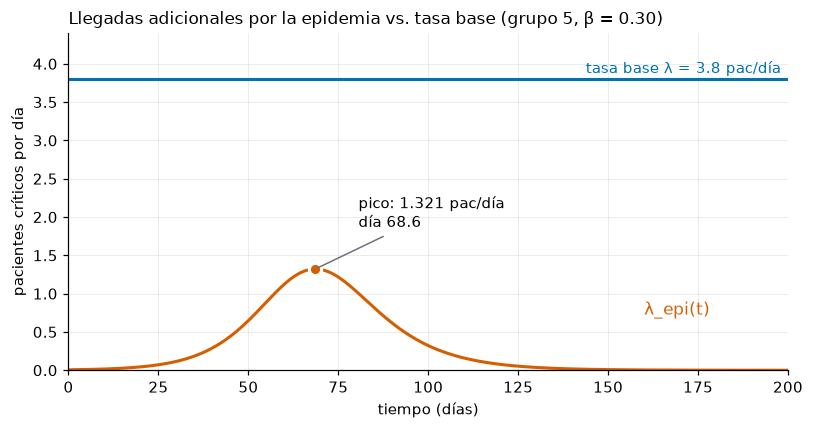

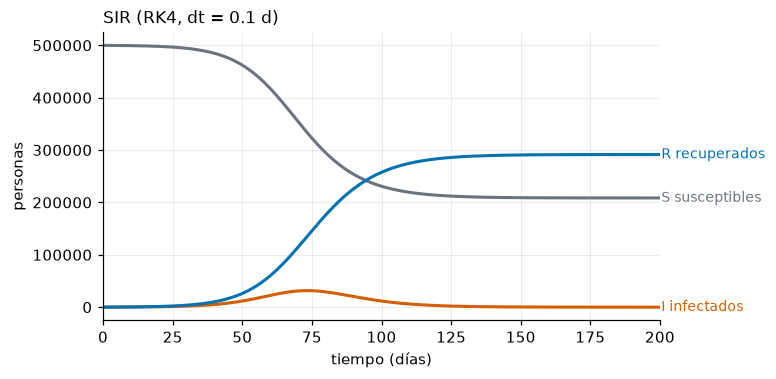

CSV escritos: ['sir_lambda_epi_diario.csv', 'sir_lambda_epi_dt0.1.csv']


In [3]:
cv = sir.integrar_sir(dt=0.1, **SIRP); pk = sir.pico(cv); ipk = sir.pico(cv, "I")
LAM_BASE = 3.8
pico_tot = LAM_BASE + pk["valor"]
RES["sir"] = {"R0": SIRP["beta"] / SIRP["gamma"], "pico_lambda_epi": pk, "pico_I": ipk, "lambda_total_en_pico": pico_tot,
              "fraccion_final_recuperados": float(cv["R"][-1] / SIRP["N"]), "S_final": float(cv["S"][-1]), "I_final": float(cv["I"][-1]),
              "lambda_epi_dia0": float(cv["lambda_epi"][0]), "razon_pico_sobre_base": pk["valor"] / LAM_BASE}
print(f"R0 = β/γ = {SIRP['beta']/SIRP['gamma']:.2f}")
print(f"Pico de λ_epi: {pk['valor']:.4f} pacientes/día en el día {pk['dia']:.1f}  (λ total = {pico_tot:.4f}; {100*pk['valor']/LAM_BASE:.1f} % de la tasa base)")
print(f"Pico de infectados I: {ipk['valor']:.0f} en el día {ipk['dia']:.1f}")
print(f"Al día 200: S={cv['S'][-1]:.0f}, I={cv['I'][-1]:.1f}, R={cv['R'][-1]:.0f} ({100*cv['R'][-1]/SIRP['N']:.1f} % de N)")
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(cv["t"], cv["lambda_epi"], color=NARANJA, lw=2); ax.axhline(LAM_BASE, color=AZUL, lw=2)
ax.text(198, LAM_BASE + 0.08, "tasa base λ = 3.8 pac/día", color=AZUL, ha="right"); ax.text(160, pk["valor"] * 0.55, "λ_epi(t)", color=NARANJA, fontsize=11)
ax.plot([pk["dia"]], [pk["valor"]], "o", color=NARANJA, ms=8, mec="white", mew=2)
ax.annotate(f"pico: {pk['valor']:.3f} pac/día\ndía {pk['dia']:.1f}", (pk["dia"], pk["valor"]), (pk["dia"] + 12, pk["valor"] + 0.55), arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set_xlabel("tiempo (días)"); ax.set_ylabel("pacientes críticos por día"); ax.set_title("Llegadas adicionales por la epidemia vs. tasa base (grupo 5, β = 0.30)", loc="left")
ax.set_xlim(0, 200); ax.set_ylim(0, 4.4); plt.tight_layout(); plt.savefig(FIG / "fig_4_1a_lambda_epi.png", dpi=160); plt.show()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for k, col, lab in [("S", GRIS, "S susceptibles"), ("I", NARANJA, "I infectados"), ("R", AZUL, "R recuperados")]:
    ax.plot(cv["t"], cv[k], color=col, lw=2); ax.text(200.5, cv[k][-1], lab, color=col, va="center", fontsize=9)
ax.set_xlim(0, 200); ax.set_xlabel("tiempo (días)"); ax.set_ylabel("personas"); ax.set_title("SIR (RK4, dt = 0.1 d)", loc="left")
plt.subplots_adjust(right=0.8); plt.savefig(FIG / "fig_4_1a_sir.png", dpi=160, bbox_inches="tight"); plt.show()
sir.exportar_csv(cv, str(DAT / "sir_lambda_epi_dt0.1.csv"), lam_base=LAM_BASE, cada=1)
cd = sir.integrar_sir(dt=1.0, **SIRP); sir.exportar_csv(cd, str(DAT / "sir_lambda_epi_diario.csv"), lam_base=LAM_BASE, cada=1)
chk = sir.cargar_csv(str(DAT / "sir_lambda_epi_dt0.1.csv"))
assert np.allclose(sir.lambda_epi_en(37.35, chk), np.interp(37.35, cv["t"], cv["lambda_epi"])) and len(chk["t_dias"]) == 2001
print("CSV escritos:", sorted(p.name for p in DAT.glob("sir_*.csv")))

In [4]:
(DAT / "task4_1a_resultados.json").write_text(json.dumps(RES, indent=2, default=lambda o: float(o) if hasattr(o, "__float__") else str(o), ensure_ascii=False))
print("Guardado: resultados/datos/task4_1a_resultados.json")

Guardado: resultados/datos/task4_1a_resultados.json


---
## Inciso 4.1b — Simulación con llegadas variables (pendiente)
Requisitos (hoja): generar llegadas con λ(t) = λ + λepi(t) por **adelgazamiento**; simular la variante **sin espera** con las camas recomendadas en el Task 3.1;
100 réplicas; reportar la probabilidad de bloqueo **en función del tiempo** y el total de pacientes desviados durante la ola, con IC.

Insumos disponibles: `resultados/datos/sir_lambda_epi_dt0.1.csv` (malla de 0.1 días; cargar con `sir.cargar_csv` y evaluar con `sir.lambda_epi_en`) y λmax ≥ 5.1213 pac/día (máximo de λ(t)).
Extensión necesaria en `src/hospital_uci/`: el gancho `interarribo(rng)` del simulador no recibe el reloj; hace falta una tasa de llegada que dependa del tiempo (adelgazamiento) y un conteo de bloqueos por ventanas de tiempo.

## Inciso 4.1c — Camas de contingencia (pendiente)
Camas adicionales necesarias para que la fracción de pacientes desviados durante la ola no supere 5 %, y cómo cambia la recomendación a la directora.

## Inciso 4.1d — Límites del modelo de un solo sentido (pendiente)
Enumerar dos fenómenos que el modelo ignora (por ejemplo, qué le ocurre a la epidemia cuando el hospital desvía pacientes) y, para cada uno, la dirección en que cambiaría la estimación y por qué.